<a href="https://www.pieriandata.com"><img src="data/Logo.jpg"></a>
*Copyright by Pierian Data Inc.*

# Feature Matching

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [3]:
def display_image(img, cmap='gray'):
    plt.figure(figsize=(12,10))
    plt.imshow(img, cmap=cmap)

In [2]:
def display(img,cmap='gray'):
    fig = plt.figure(figsize=(12,10))
    ax = fig.add_subplot(111)
    ax.imshow(img,cmap='gray')

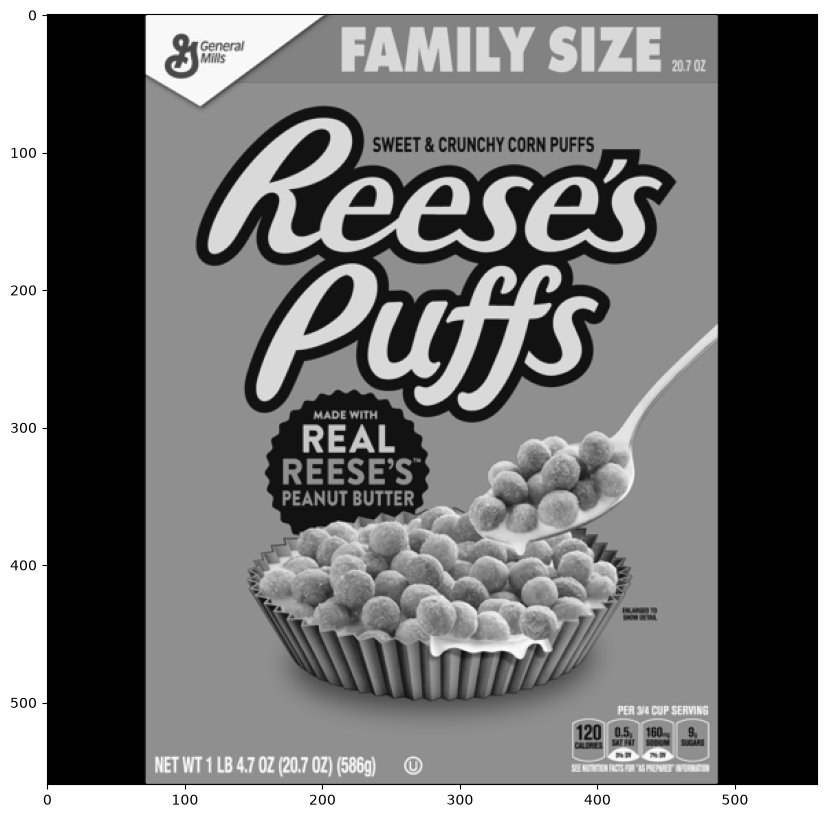

In [4]:
reeses = cv2.imread('data/reeses_puffs.png', 0)
display_image(reeses)

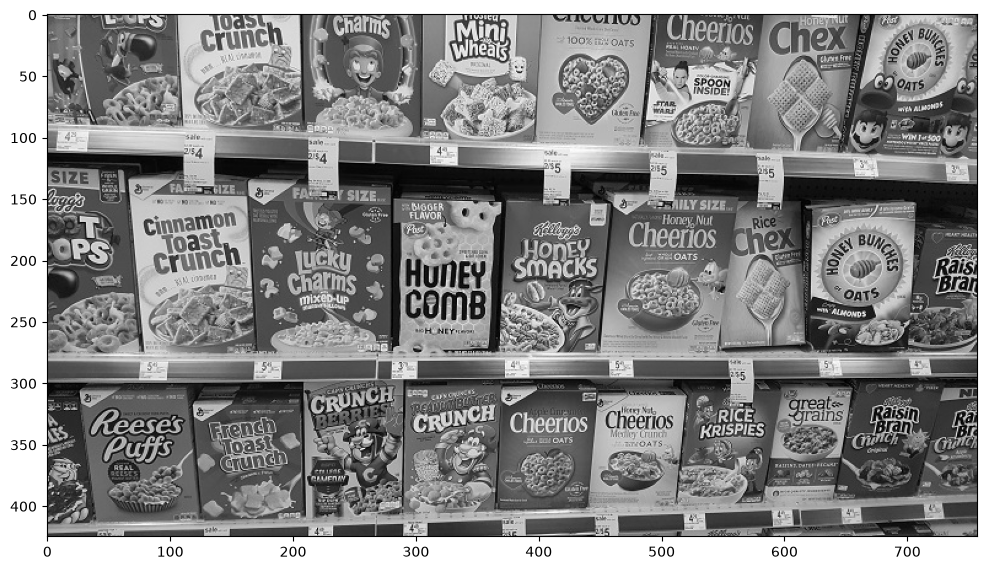

In [5]:
cereals = cv2.imread('data/many_cereals.jpg', 0)
display_image(cereals)

--------
# Brute Force Detection with ORB Descriptors

**`orb.detectAndCompute()`**  
The function performs two tasks:  
1. **Detect keypoints** — finds distinctive points in the image, such as corners and textured regions.
2. **Compute descriptors** — creates a numerical description of the local image pattern around each keypoint.

It returns two outputs: `kp1` and `des1`.  

`kp1` — Keypoints  
A list of detected keypoint objects. Each keypoint contains information such as its position, size, orientation, and response strength.  

`des1` — Descriptors  
A NumPy array containing the binary descriptors associated with the detected keypoints.  
With standard ORB settings, each descriptor is 32 bytes (256 bits).  

In [7]:
# Creates the ORB feature detector and descriptor extractor
orb = cv2.ORB_create()

# Find the keypoints and descriptors with ORB
kp1, des1 = orb.detectAndCompute(image=reeses, mask=None)
kp2, des2 = orb.detectAndCompute(image=cereals, mask=None)

1. cv2.BFMatcher()
BFMatcher stands for Brute-Force Matcher.
It compares the descriptor of each keypoint in one image against descriptors in another image to find the most similar features.
For example, if you have two images of the same object, it can help identify which features correspond to each other.
2. cv2.NORM_HAMMING
This specifies the distance metric used to compare descriptors.
ORB produces binary descriptors, so Hamming distance is appropriate.
Example:
Descriptor A
1

0

1

1

0

0

1

0


Descriptor B
1

1

1

0

0

0

1

0


Two bits differ, so the Hamming distance is 2.

Hamming distance counts the number of bit positions that differ. A smaller distance generally means the descriptors are more similar.
3. crossCheck=True
This enables mutual best matching.
A descriptor in image 1 must select a descriptor in image 2 as its best match, and that descriptor in image 2 must also select the original descriptor as its best match.
- crossCheck=True: keeps only mutual best matches.
- crossCheck=False: allows one-way nearest-neighbor matching, which can return more candidates.
Cross-checking often removes ambiguous matches, but it does not guarantee that every remaining match is correct.

In [7]:
# Initiate ORB detector
orb = cv2.ORB_create()

# find the keypoints and descriptors with ORB
kp1, des1 = orb.detectAndCompute(reeses,None)
kp2, des2 = orb.detectAndCompute(cereals,None)

# create BFMatcher object
bf = cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=True)

# Match descriptors.
matches = bf.match(des1,des2)

# Sort them in the order of their distance.
matches = sorted(matches, key = lambda x:x.distance)

# Draw first 25 matches.
reeses_matches = cv2.drawMatches(reeses,kp1,cereals,kp2,matches[:25],None,flags=2)

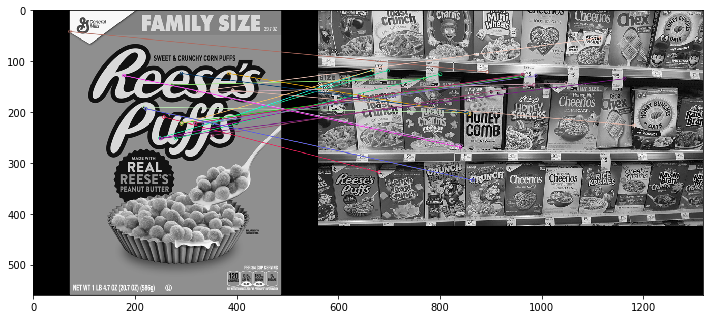

In [8]:
display(reeses_matches)

# Brute-Force Matching with SIFT Descriptors and Ratio Test

In [9]:
# Create SIFT Object
sift = cv2.xfeatures2d.SIFT_create()

# find the keypoints and descriptors with SIFT
kp1, des1 = sift.detectAndCompute(reeses,None)
kp2, des2 = sift.detectAndCompute(cereals,None)

# BFMatcher with default params
bf = cv2.BFMatcher()
matches = bf.knnMatch(des1,des2, k=2)

# Apply ratio test
good = []
for match1,match2 in matches:
    if match1.distance < 0.75*match2.distance:
        good.append([match1])

# cv2.drawMatchesKnn expects list of lists as matches.
sift_matches = cv2.drawMatchesKnn(reeses,kp1,cereals,kp2,good,None,flags=2)

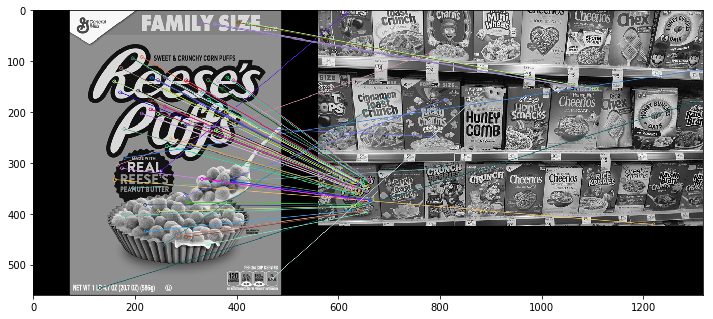

In [10]:
display(sift_matches)

# FLANN based Matcher

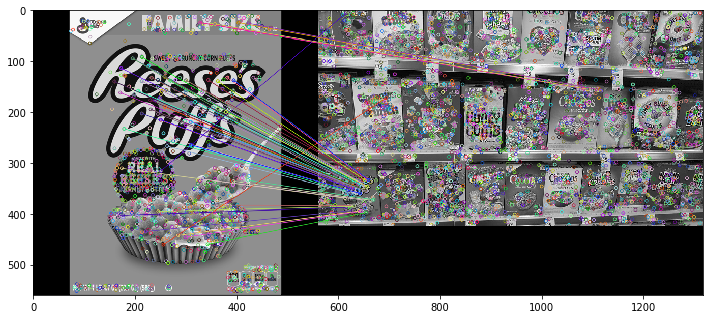

In [18]:
# Initiate SIFT detector
sift = cv2.xfeatures2d.SIFT_create()

# find the keypoints and descriptors with SIFT
kp1, des1 = sift.detectAndCompute(reeses,None)
kp2, des2 = sift.detectAndCompute(cereals,None)

# FLANN parameters
FLANN_INDEX_KDTREE = 0
index_params = dict(algorithm = FLANN_INDEX_KDTREE, trees = 5)
search_params = dict(checks=50)  

flann = cv2.FlannBasedMatcher(index_params,search_params)

matches = flann.knnMatch(des1,des2,k=2)

good = []

# ratio test
for i,(match1,match2) in enumerate(matches):
    if match1.distance < 0.7*match2.distance:
        
        good.append([match1])


flann_matches = cv2.drawMatchesKnn(reeses,kp1,cereals,kp2,good,None,flags=0)

display(flann_matches)

In [12]:
# Initiate SIFT detector
sift = cv2.xfeatures2d.SIFT_create()

# find the keypoints and descriptors with SIFT
kp1, des1 = sift.detectAndCompute(reeses,None)
kp2, des2 = sift.detectAndCompute(cereals,None)

# FLANN parameters
FLANN_INDEX_KDTREE = 0
index_params = dict(algorithm = FLANN_INDEX_KDTREE, trees = 5)
search_params = dict(checks=50)  

flann = cv2.FlannBasedMatcher(index_params,search_params)

matches = flann.knnMatch(des1,des2,k=2)

# Need to draw only good matches, so create a mask
matchesMask = [[0,0] for i in range(len(matches))]

# ratio test
for i,(match1,match2) in enumerate(matches):
    if match1.distance < 0.7*match2.distance:
        matchesMask[i]=[1,0]

draw_params = dict(matchColor = (0,255,0),
                   singlePointColor = (255,0,0),
                   matchesMask = matchesMask,
                   flags = 0)

flann_matches = cv2.drawMatchesKnn(reeses,kp1,cereals,kp2,matches,None,**draw_params)

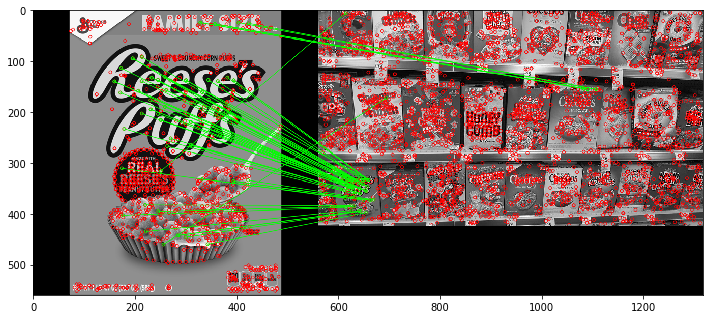

In [13]:
display(flann_matches)